# Задание 2.7
## Обобщённые биномиальные коэффициенты

### Условие:
Напомним, $C_n^k=\dfrac{n!}{k!(n-k)!}$, а $n!=\Gamma(n+1)$, где $\Gamma(z)=\displaystyle\int_0^\infty x^{z-1}e^{-x}\,dx$, $\operatorname{Re}z>0$ (для остальных $z$ — аналитическое продолжение). Для $z,w\in\mathbb C$ положим
$$
C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)}.
$$
a) Найдите $C_{1+i}^{1-i}$. b) Найдите $\operatorname{Arg}\bigl(C_{1+i}^{1-i}\bigr)$. c) Постройте линии уровня $\operatorname{Arg}\bigl[C_z^{1/z}\bigr]=\text{const}$, где $z=x+iy$.

### Решение:
**a), b)** Подставляем $z=1+i$, $w=1-i$: $z+1=2+i$, $w+1=2-i$, $z-w+1=1+2i$, откуда
$$
C_{1+i}^{1-i}=\frac{\Gamma(2+i)}{\Gamma(2-i)\,\Gamma(1+2i)}.
$$
Гамма-функцию считаем двумя независимыми способами: `scipy.special.gamma` (двойная точность) и `mpmath.gamma` (произвольная точность).

In [4]:
import numpy as np
from scipy.special import gamma
import mpmath as mp

def C(z, w):
    return gamma(z + 1)/(gamma(w + 1)*gamma(z - w + 1))

z, w = 1 + 1j, 1 - 1j
val = C(z, w)
print('scipy :', val)

mp.mp.dps = 25
val_mp = mp.gamma(2 + 1j)/(mp.gamma(2 - 1j)*mp.gamma(1 + 2j))
print('mpmath:', val_mp)

print()
print(f'a) C = {val.real:.5f} + {val.imag:.5f}i')
print(f'b) Arg C = {np.angle(val):.6f} рад = {np.degrees(np.angle(val)):.4f}°')
print(f'   |C|   = {abs(val):.6f}')

scipy : (4.36744914064015+4.8516297651578295j)
mpmath: (4.367449140640138967228261 + 4.851629765157811540851968j)

a) C = 4.36745 + 4.85163i
b) Arg C = 0.837869 рад = 48.0064°
   |C|   = 6.527857


**c)** Здесь $w=1/z$, то есть
$$
C_z^{1/z}=\frac{\Gamma(z+1)}{\Gamma\!\bigl(\tfrac1z+1\bigr)\,\Gamma\!\bigl(z-\tfrac1z+1\bigr)}.
$$
Значения $\Gamma$ велики, поэтому считаем аргумент через логарифм: $\operatorname{Arg}C=\operatorname{Im}\bigl[\ln\Gamma(z+1)-\ln\Gamma(\tfrac1z+1)-\ln\Gamma(z-\tfrac1z+1)\bigr]\pmod{2\pi}$ (`scipy.special.loggamma`).
Линию уровня $\operatorname{Arg}C=c$ задаёт уравнение $\sin(\theta-c)=0$ при $\cos(\theta-c)>0$, где $\theta$ — мнимая часть логарифма; так линии не искажаются скачком аргумента на $\pm\pi$. Цвет на рисунке показывает значение $\operatorname{Arg}C\in(-\pi,\pi]$.

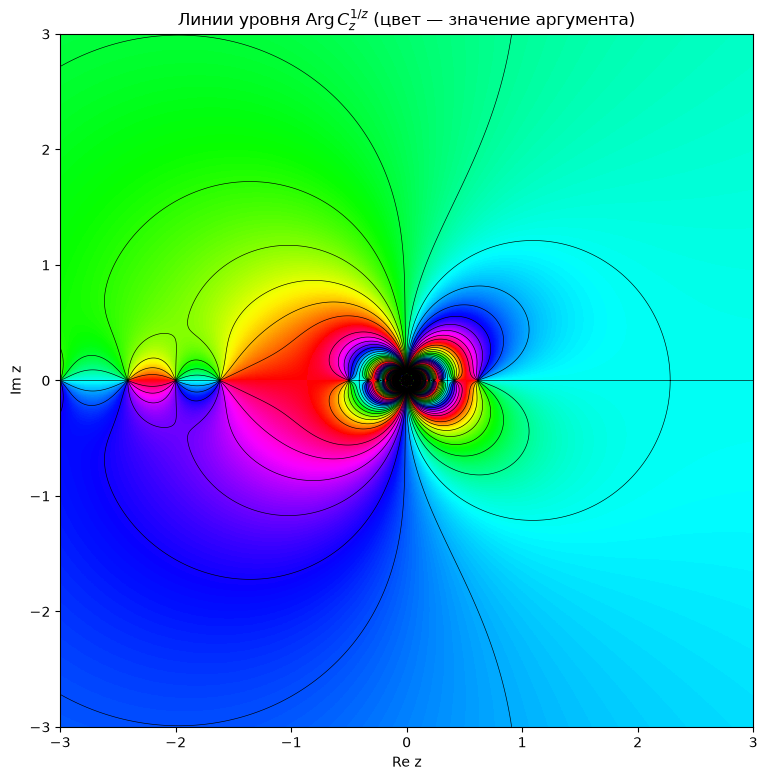

In [5]:
import matplotlib.pyplot as plt
from scipy.special import loggamma

def theta(z):
    with np.errstate(all='ignore'):
        L = loggamma(z + 1) - loggamma(1/z + 1) - loggamma(z - 1/z + 1)
    return L.imag

lim, n = 3.0, 1800
xs = np.linspace(-lim, lim, n)
X, Y = np.meshgrid(xs, xs)
Z = X + 1j*Y
th = theta(Z)
arg = np.angle(np.exp(1j*th))                 # значение Arg в (−π, π]
arg[~np.isfinite(th)] = np.nan

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(arg, extent=[-lim, lim, -lim, lim], origin='lower', cmap='hsv', vmin=-np.pi, vmax=np.pi,
          interpolation='nearest')
for c in np.arange(-7, 8)*np.pi/8:
    S = np.sin(th - c)
    S[np.cos(th - c) <= 0] = np.nan
    ax.contour(X, Y, S, levels=[0], colors='k', linewidths=0.45)
ax.set_xlabel('Re z'); ax.set_ylabel('Im z')
ax.set_title(r'Линии уровня $\mathrm{Arg}\,C_z^{1/z}$ (цвет — значение аргумента)')
plt.show()

Увеличим окрестность начала координат: из-за $1/z$ в аргументе функции там линии уровня сгущаются (существенная особенность в $z=0$).

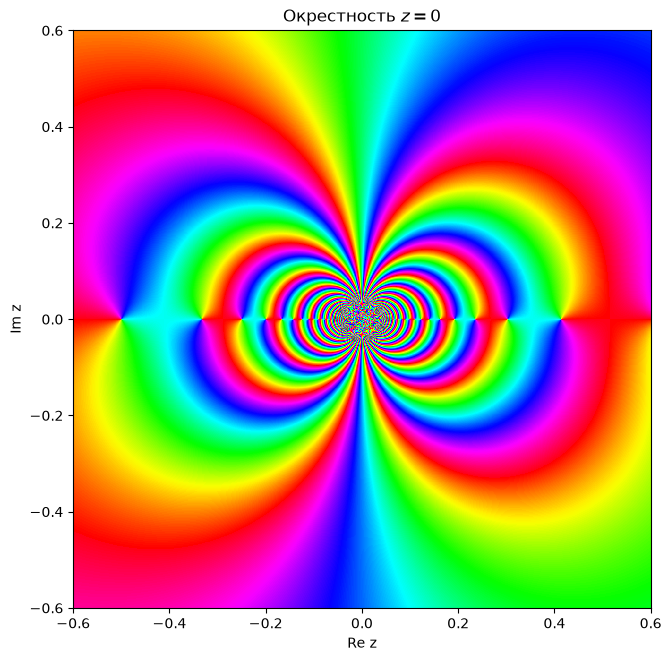

In [6]:
lim, n = 0.6, 1800
xs = np.linspace(-lim, lim, n)
X, Y = np.meshgrid(xs, xs)
Z = X + 1j*Y
th = theta(Z)
arg = np.angle(np.exp(1j*th)); arg[~np.isfinite(th)] = np.nan

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(arg, extent=[-lim, lim, -lim, lim], origin='lower', cmap='hsv', vmin=-np.pi, vmax=np.pi,
          interpolation='nearest')
ax.set_xlabel('Re z'); ax.set_ylabel('Im z'); ax.set_title('Окрестность $z=0$')
plt.show()

### Ответ:

a) $C_{1+i}^{1-i}=\dfrac{\Gamma(2+i)}{\Gamma(2-i)\Gamma(1+2i)}\approx\mathbf{4{,}36745+4{,}85163\,i}$;

b) $\operatorname{Arg}\bigl(C_{1+i}^{1-i}\bigr)\approx\mathbf{0{,}837869}$ рад $\approx48{,}0064^\circ$;

c) линии уровня функции $\operatorname{Arg}C_z^{1/z}$ построены выше; картина симметрична относительно вещественной оси, а вблизи $z=0$ линии бесконечно сгущаются.